# Governing False Accusations and Abstention in AI Text Detection

**End-to-end reproducible CPU notebook** — HC3 primary benchmark; optional ChatGPT-Detector-Bias (TOEFL/Hewlett/ASAP) and RAID external evaluation.

**How to run:** in Kaggle, enable Internet and select CPU; then choose **Run All**. In local Jupyter, ensure Internet access is enabled. The pipeline creates `false_accusation_results/` and `false_accusation_results.zip`.

**Research questions**
- **RQ1:** Human false-positive rates across language/script proxy, domain, and response length, with bootstrap confidence intervals.
- **RQ2:** HC3 held-out source-domain evaluation and a bounded cross-dataset RAID evaluation when labelled human/AI records are available.
- **RQ3:** TOEFL versus Hewlett/ASAP human essay audit when the public metadata file contains the expected records.
- **RQ4:** Validation-calibrated abstention and its coverage / false-positive trade-off.
- **RQ5:** Evidence, response, human-review, and appeal safeguards.

**Important:** this is a research benchmark, not a commercial detector or a tool for accusing students. External dataset steps are guarded: if a source is unavailable or its schema differs, the notebook reports the skip rather than crashing or fabricating results.

FALSE ACCUSATION PROJECT — RUN CONFIGURATION
Python: 3.13.16
Working directory: /kaggle/working
Results directory: /kaggle/working/false_accusation_results
Random seed: 42 | CPU baseline | Max TF-IDF features: 50000
Using cached file: hc3_all.jsonl

HC3 prepared successfully
Source question records: 24322
Answer rows: 85431
Unique question groups: 24322
Class counts:
 class
Human    58546
AI       26885
Mean / median word count: 137.89 / 112


,metric,value
0,source_question_records,24322.00
1,answer_responses,85431.00
2,human_responses,58546.00
3,AI_responses,26885.00
4,unique_question_groups,24322.00
5,source_domains,5.00
6,mean_words,137.89
7,median_words,112.00


CSV saved: hc3_dataset_overview.csv


class,domain,AI,Human
0,finance,4503,3933
1,medicine,1334,1248
2,open_qa,3546,1187
3,reddit_eli5,16660,51336
4,wiki_csai,842,842


CSV saved: hc3_domain_class_counts.csv


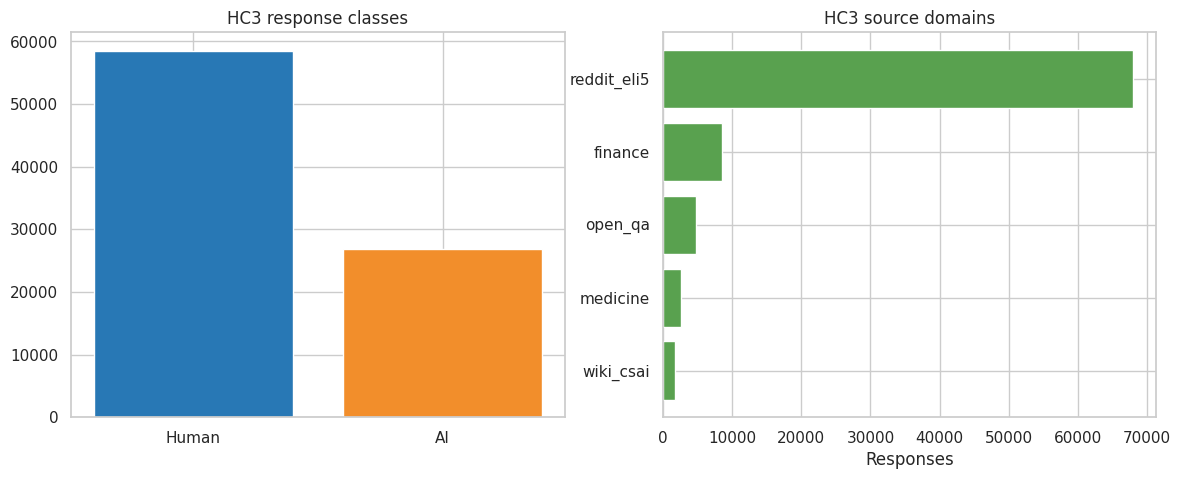

PDF saved: figure_01_hc3_profile.pdf


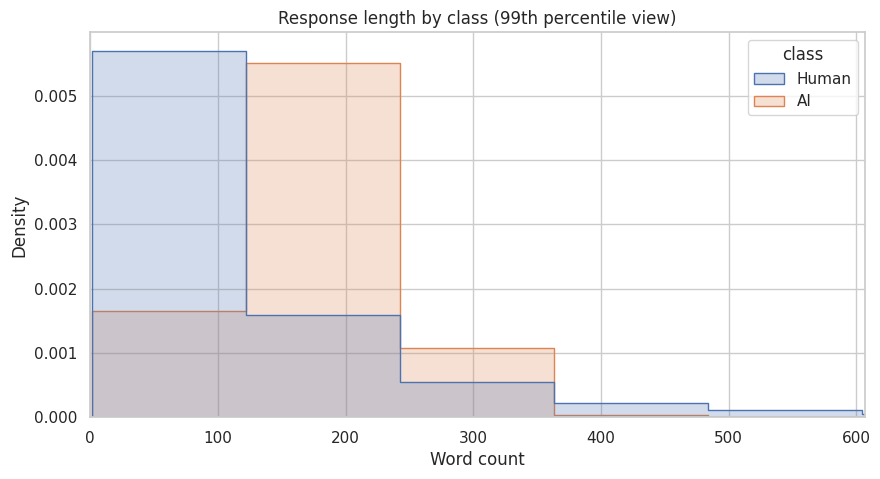

PDF saved: figure_02_hc3_length.pdf


,split,rows,question_groups,human,AI
0,train,54687,15565,37527,17160
1,validation,13665,3892,9336,4329
2,test,17079,4865,11683,5396


CSV saved: hc3_grouped_split_summary.csv
Question-group leakage check: PASSED

Training TF-IDF + logistic-regression baseline (CPU)...


,n,threshold,accuracy,balanced_accuracy,precision_ai,recall_ai,f1_ai,roc_auc,false_positive_rate_human,false_negative_rate_ai,tn,fp,fn,tp
0,17079,0.5,0.981908,0.984681,0.9525,0.992216,0.971952,0.996296,0.022854,0.007784,11416,267,42,5354


CSV saved: hc3_grouped_test_metrics.csv
CSV saved: hc3_classification_report.csv

RQ1 — Human false-positive rates by language proxy, domain, and length


,group_variable,group,n_human,false_positive_rate,ci_95_lower,ci_95_upper,small_n_lt_30
0,language_proxy,Latin-script-dominant,11683,0.022854,0.020200,0.025509,False
1,domain,finance,769,0.136541,0.113134,0.161281,False
2,domain,medicine,262,0.053435,0.030439,0.083969,False
3,domain,open_qa,242,0.128099,0.090909,0.177686,False
4,domain,reddit_eli5,10227,0.000587,0.000196,0.001076,False
5,domain,wiki_csai,183,0.606557,0.540847,0.677596,False
6,length_band,0–50,4084,0.009794,0.007101,0.012733,False
7,length_band,51–150,4718,0.014837,0.011446,0.018440,False
8,length_band,151–300,1928,0.042012,0.033195,0.050311,False
9,length_band,301–600,765,0.084967,0.065359,0.105882,False


CSV saved: rq1_false_accusation_subgroups.csv


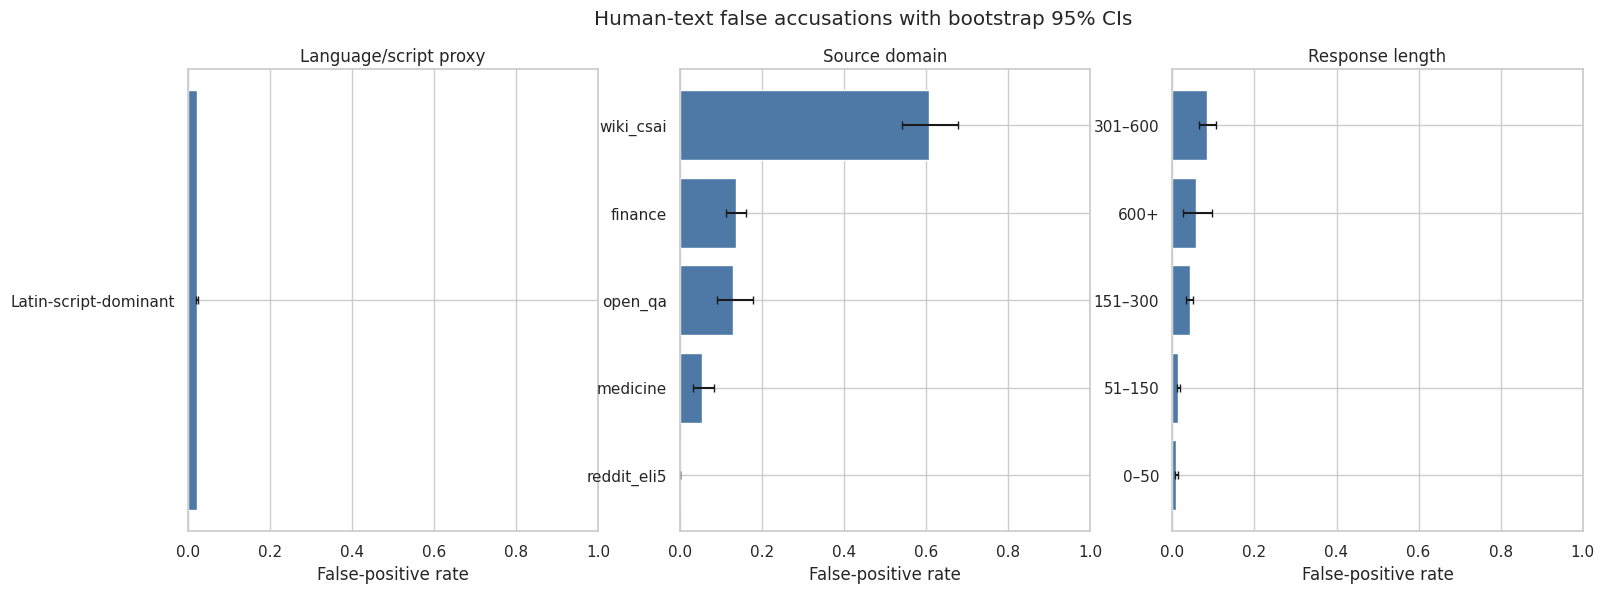

PDF saved: figure_03_rq1_subgroups.pdf

RQ2 — Held-out HC3 source-domain evaluation


In [ ]:
# ================================================================
# FALSE ACCUSATION PROJECT — END-TO-END RESEARCH PIPELINE
# Run this notebook from top to bottom (Kernel -> Restart & Run All).
# Primary dataset: HC3. Optional external datasets: detector-bias and RAID.
# This is a benchmark study, NOT a tool for accusing real students.
# ================================================================

import os, sys, re, json, random, warnings, zipfile, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

# Works in Kaggle, Colab, or a local Jupyter environment.
if Path("/kaggle/working").exists():
    WORK = Path("/kaggle/working")
elif Path("/content").exists():
    WORK = Path("/content")
else:
    WORK = Path.cwd()

OUT = WORK / "false_accusation_results"
FIG = OUT / "figures"
TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# Limits keep the optional external data tasks bounded on CPU.
MAX_FEATURES = 50000
RAID_PER_CLASS = 1500
RAID_SCAN_LIMIT = 250000
BIAS_GROUP_LIMIT = 5000

print("=" * 72)
print("FALSE ACCUSATION PROJECT — RUN CONFIGURATION")
print("Python:", sys.version.split()[0])
print("Working directory:", WORK)
print("Results directory:", OUT)
print("Random seed:", SEED, "| CPU baseline | Max TF-IDF features:", MAX_FEATURES)
print("=" * 72)

# ---------------------------- HELPERS ----------------------------
def clean_text(value):
    if value is None:
        return ""
    if isinstance(value, list):
        value = " ".join(str(v) for v in value)
    if isinstance(value, float) and np.isnan(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()


def word_count(value):
    return len(re.findall(r"\b\w+\b", clean_text(value), flags=re.UNICODE))


def lexical_diversity(value):
    words = re.findall(r"\b[a-zA-Z]+\b", clean_text(value).lower())
    return len(set(words)) / len(words) if words else np.nan


def save_csv(frame, filename):
    path = TAB / filename
    frame.to_csv(path, index=False)
    print("CSV saved:", path.name)
    return path


def save_pdf(fig, filename):
    path = FIG / filename
    fig.savefig(path, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("PDF saved:", path.name)
    return path


def bootstrap_mean_ci(values, n_boot=1000):
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        return np.nan, np.nan, np.nan, 0
    rng = np.random.default_rng(SEED)
    means = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        means[i] = rng.choice(arr, size=arr.size, replace=True).mean()
    return (float(arr.mean()), float(np.quantile(means, .025)),
            float(np.quantile(means, .975)), int(arr.size))


def calculate_metrics(y_true, probabilities, threshold=0.5):
    y = np.asarray(y_true, dtype=int)
    p = np.asarray(probabilities, dtype=float)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y, p) if np.unique(y).size == 2 else np.nan
    human_n = int((y == 0).sum())
    return {
        "n": int(len(y)), "threshold": float(threshold),
        "accuracy": float(accuracy_score(y, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
        "precision_ai": float(precision_score(y, pred, zero_division=0)),
        "recall_ai": float(recall_score(y, pred, zero_division=0)),
        "f1_ai": float(f1_score(y, pred, zero_division=0)),
        "roc_auc": float(auc) if np.isfinite(auc) else np.nan,
        "false_positive_rate_human": float(fp / human_n) if human_n else np.nan,
        "false_negative_rate_ai": float(fn / (fn + tp)) if (fn + tp) else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }


def make_baseline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 5), min_df=2,
            max_features=MAX_FEATURES, sublinear_tf=True,
            dtype=np.float32
        )),
        ("classifier", LogisticRegression(
            max_iter=700, class_weight="balanced", solver="liblinear",
            random_state=SEED
        ))
    ])


def fit_calibrated_classifier(estimator, X, y):
    # sklearn renamed base_estimator to estimator; support both versions.
    try:
        calibrated = CalibratedClassifierCV(estimator=estimator, method="sigmoid", cv=3)
    except TypeError:
        calibrated = CalibratedClassifierCV(base_estimator=estimator, method="sigmoid", cv=3)
    calibrated.fit(X, y)
    return calibrated


def safe_download(url, destination, timeout=300):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 0:
        print("Using cached file:", destination.name)
        return destination
    print("Downloading:", url)
    response = requests.get(url, timeout=timeout, stream=True)
    response.raise_for_status()
    tmp = destination.with_suffix(destination.suffix + ".part")
    with open(tmp, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
    tmp.replace(destination)
    print("Download complete:", destination.name)
    return destination

# ------------------------- 1. LOAD HC3 ----------------------------
HC3_URL = "https://huggingface.co/datasets/Hello-SimpleAI/HC3/resolve/main/all.jsonl"
HC3_FILE = WORK / "hc3_all.jsonl"
hc3_path = safe_download(HC3_URL, HC3_FILE)

rows = []
source_questions = 0
with open(hc3_path, "r", encoding="utf-8") as handle:
    for i, line in enumerate(handle):
        line = line.strip()
        if not line:
            continue
        record = json.loads(line)
        source_questions += 1
        qid = record.get("id")
        if qid is None or str(qid).strip() == "" or str(qid).lower() == "none":
            qid = record.get("index")
        if qid is None or str(qid).strip() == "" or str(qid).lower() == "none":
            qid = f"hc3_question_{i}"
        qid = str(qid)
        domain = clean_text(record.get("source")) or "unknown"
        question = clean_text(record.get("question"))
        for answer in (record.get("human_answers") or []):
            text_value = clean_text(answer)
            if text_value:
                rows.append({"question_id": qid, "domain": domain,
                             "question": question, "text": text_value,
                             "label": 0, "class": "Human"})
        for answer in (record.get("chatgpt_answers") or []):
            text_value = clean_text(answer)
            if text_value:
                rows.append({"question_id": qid, "domain": domain,
                             "question": question, "text": text_value,
                             "label": 1, "class": "AI"})

hc3 = pd.DataFrame(rows)
if hc3.empty:
    raise RuntimeError("HC3 loaded but contained no usable human/ChatGPT answer records.")
hc3["word_count"] = hc3["text"].map(word_count)
hc3["lexical_diversity"] = hc3["text"].map(lexical_diversity)

def language_script_proxy(text):
    value = clean_text(text)
    cjk = len(re.findall(r"[\u4e00-\u9fff]", value))
    latin = len(re.findall(r"[A-Za-z]", value))
    return "Chinese-script-dominant" if cjk > latin else "Latin-script-dominant"

hc3["language_proxy"] = hc3["text"].map(language_script_proxy)
hc3["length_band"] = pd.cut(
    hc3["word_count"], bins=[-1, 50, 150, 300, 600, np.inf],
    labels=["0–50", "51–150", "151–300", "301–600", "600+"]
)

print("\nHC3 prepared successfully")
print("Source question records:", source_questions)
print("Answer rows:", len(hc3))
print("Unique question groups:", hc3.question_id.nunique())
print("Class counts:\n", hc3["class"].value_counts().to_string())
print("Mean / median word count:", round(hc3.word_count.mean(), 2), "/", int(hc3.word_count.median()))

# Dataset overview
overview = pd.DataFrame([
    {"metric": "source_question_records", "value": source_questions},
    {"metric": "answer_responses", "value": len(hc3)},
    {"metric": "human_responses", "value": int((hc3.label == 0).sum())},
    {"metric": "AI_responses", "value": int((hc3.label == 1).sum())},
    {"metric": "unique_question_groups", "value": hc3.question_id.nunique()},
    {"metric": "source_domains", "value": hc3.domain.nunique()},
    {"metric": "mean_words", "value": round(hc3.word_count.mean(), 2)},
    {"metric": "median_words", "value": round(hc3.word_count.median(), 2)}
])
display(overview)
save_csv(overview, "hc3_dataset_overview.csv")
domain_counts = hc3.groupby(["domain", "class"]).size().unstack(fill_value=0).reset_index()
display(domain_counts)
save_csv(domain_counts, "hc3_domain_class_counts.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_counts = hc3["class"].value_counts().reindex(["Human", "AI"], fill_value=0)
axes[0].bar(class_counts.index, class_counts.values, color=["#2878B5", "#F28E2B"])
axes[0].set_title("HC3 response classes")
counts_by_domain = hc3.groupby("domain").size().sort_values()
axes[1].barh(counts_by_domain.index.astype(str), counts_by_domain.values, color="#59A14F")
axes[1].set_title("HC3 source domains")
axes[1].set_xlabel("Responses")
save_pdf(fig, "figure_01_hc3_profile.pdf")

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=hc3, x="word_count", hue="class", bins=50,
             stat="density", common_norm=False, element="step", ax=ax)
ax.set_xlim(0, max(10, float(hc3.word_count.quantile(.99))))
ax.set_title("Response length by class (99th percentile view)")
ax.set_xlabel("Word count")
save_pdf(fig, "figure_02_hc3_length.pdf")

# ------------------- 2. GROUPED TRAIN/VALIDATION/TEST ------------
# Split by question ID to keep paired answers together.
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tv_idx, test_idx = next(gss_test.split(hc3, hc3.label, groups=hc3.question_id))
tv = hc3.iloc[tv_idx].reset_index(drop=True)
test = hc3.iloc[test_idx].reset_index(drop=True)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + 1)
train_idx, val_idx = next(gss_val.split(tv, tv.label, groups=tv.question_id))
train = tv.iloc[train_idx].reset_index(drop=True)
val = tv.iloc[val_idx].reset_index(drop=True)

# Verify disjoint question groups and both classes in each partition.
assert set(train.question_id).isdisjoint(set(val.question_id))
assert set(train.question_id).isdisjoint(set(test.question_id))
assert set(val.question_id).isdisjoint(set(test.question_id))
for split_name, split_df in [("train", train), ("validation", val), ("test", test)]:
    if split_df.label.nunique() < 2:
        raise RuntimeError(f"{split_name} split has only one class; inspect source grouping before training.")

split_summary = pd.DataFrame([
    {"split": name, "rows": len(part), "question_groups": part.question_id.nunique(),
     "human": int((part.label == 0).sum()), "AI": int((part.label == 1).sum())}
    for name, part in [("train", train), ("validation", val), ("test", test)]
])
display(split_summary)
save_csv(split_summary, "hc3_grouped_split_summary.csv")
print("Question-group leakage check: PASSED")

# --------------------------- 3. BASELINE --------------------------
print("\nTraining TF-IDF + logistic-regression baseline (CPU)...")
base_pipeline = make_baseline()
calibrated_model = fit_calibrated_classifier(base_pipeline, train.text, train.label)
val_prob = calibrated_model.predict_proba(val.text)[:, 1]
test_prob = calibrated_model.predict_proba(test.text)[:, 1]
test_metrics = calculate_metrics(test.label, test_prob, 0.50)
display(pd.DataFrame([test_metrics]))
save_csv(pd.DataFrame([test_metrics]), "hc3_grouped_test_metrics.csv")

report = classification_report(
    test.label, (test_prob >= 0.5).astype(int),
    labels=[0, 1], target_names=["Human", "AI"],
    output_dict=True, zero_division=0
)
save_csv(pd.DataFrame(report).T.rename_axis("class").reset_index(), "hc3_classification_report.csv")

# --------------------------- 4. RQ1 -------------------------------
print("\nRQ1 — Human false-positive rates by language proxy, domain, and length")
human_test = test.loc[test.label == 0].copy()
human_test["ai_score"] = test_prob[test.label.to_numpy() == 0]
human_test["false_accusation"] = (human_test.ai_score >= 0.50).astype(int)

def subgroup_table(data, column):
    records = []
    for group_value, subset in data.groupby(column, observed=False, dropna=False):
        mean, low, high, n = bootstrap_mean_ci(subset.false_accusation.values)
        records.append({"group_variable": column, "group": str(group_value),
                        "n_human": n, "false_positive_rate": mean,
                        "ci_95_lower": low, "ci_95_upper": high,
                        "small_n_lt_30": n < 30})
    return pd.DataFrame(records)

rq1 = pd.concat([
    subgroup_table(human_test, "language_proxy"),
    subgroup_table(human_test, "domain"),
    subgroup_table(human_test, "length_band")
], ignore_index=True)
display(rq1)
save_csv(rq1, "rq1_false_accusation_subgroups.csv")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, column, title in zip(
    axes, ["language_proxy", "domain", "length_band"],
    ["Language/script proxy", "Source domain", "Response length"]
):
    part = rq1[rq1.group_variable == column].sort_values("false_positive_rate")
    if len(part):
        xerr = np.vstack([
            np.maximum(0, part.false_positive_rate - part.ci_95_lower),
            np.maximum(0, part.ci_95_upper - part.false_positive_rate)
        ])
        ax.barh(part.group, part.false_positive_rate, xerr=xerr, capsize=3, color="#4E79A7")
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("False-positive rate")
fig.suptitle("Human-text false accusations with bootstrap 95% CIs")
save_pdf(fig, "figure_03_rq1_subgroups.pdf")

# --------------------------- 5. RQ2 HC3 ----------------------------
print("\nRQ2 — Held-out HC3 source-domain evaluation")
# Select the largest domain using counts only, before examining its model score.
heldout_domain = hc3.domain.value_counts().idxmax()
ood_train = hc3.loc[hc3.domain != heldout_domain].copy()
ood_test = hc3.loc[hc3.domain == heldout_domain].copy()
if len(ood_train) and len(ood_test) and ood_train.label.nunique() == 2 and ood_test.label.nunique() == 2:
    ood_model = make_baseline()
    ood_model.fit(ood_train.text, ood_train.label)
    ood_prob = ood_model.predict_proba(ood_test.text)[:, 1]
    ood_metrics = calculate_metrics(ood_test.label, ood_prob, 0.50)
    rq2_hc3 = pd.DataFrame([
        {"evaluation": "Question-grouped random test", **test_metrics},
        {"evaluation": f"Held-out source domain: {heldout_domain}", **ood_metrics}
    ])
    display(rq2_hc3)
    save_csv(rq2_hc3, "rq2_hc3_random_vs_heldout_domain.csv")
    plot_data = rq2_hc3.melt(id_vars="evaluation",
        value_vars=["accuracy", "roc_auc", "false_positive_rate_human"],
        var_name="metric", value_name="score")
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=plot_data, x="metric", y="score", hue="evaluation", ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title("Random evaluation versus held-out source domain")
    save_pdf(fig, "figure_04_rq2_domain_shift.pdf")
else:
    ood_metrics = {}
    print("RQ2 held-out domain model skipped: one partition lacks both classes.")
    print("Held-out domain:", heldout_domain, "| train rows:", len(ood_train), "| test rows:", len(ood_test))

# --------------------------- 6. RQ3 -------------------------------
print("\nRQ3 — TOEFL human essay audit (single-group descriptive analysis)")
BIAS_URL = "https://huggingface.co/datasets/WxWx/ChatGPT-Detector-Bias/resolve/main/all_data.json"
BIAS_FILE = WORK / "chatgpt_detector_bias_all_data.json"
audit = pd.DataFrame()
rq3_summary = pd.DataFrame()
rq3_comparison_complete = False
rq3_toefl_only_complete = False
try:
    bias_path = safe_download(BIAS_URL, BIAS_FILE, timeout=300)
    with open(bias_path, "r", encoding="utf-8") as f:
        bias_payload = json.load(f)
    if isinstance(bias_payload, list):
        bias = pd.DataFrame(bias_payload)
    elif isinstance(bias_payload, dict):
        candidate = bias_payload.get("data", bias_payload.get("records", []))
        bias = pd.DataFrame(candidate if isinstance(candidate, list) else [])
    else:
        bias = pd.DataFrame()

    required = {"text", "domain", "kind"}
    if required.issubset(bias.columns):
        human_mask = bias.kind.astype(str).str.contains("human", case=False, na=False)
        domain_text = bias.domain.astype(str)
        toefl_mask = domain_text.str.contains("TOEFL_real", case=False, regex=False, na=False)
        # RQ3 is intentionally TOEFL-only: no verified Hewlett/ASAP dataset
        # was available for this project run.
        audit = bias.loc[human_mask & toefl_mask].copy()
        audit["writer_group"] = "TOEFL human essays"
        audit["text"] = audit.text.map(clean_text)
        audit = audit.loc[audit.text.str.len() > 0].copy()
        # Deterministic cap per group to keep inference bounded.
        audit = (audit.groupby("writer_group", group_keys=False)
                      .apply(lambda x: x.sample(n=min(len(x), BIAS_GROUP_LIMIT), random_state=SEED))
                      .reset_index(drop=True)) if len(audit) else audit

        if len(audit):
            audit["word_count"] = audit.text.map(word_count)
            audit["lexical_diversity"] = audit.text.map(lexical_diversity)
            audit["ai_score"] = calibrated_model.predict_proba(audit.text)[:, 1]
            audit["false_accusation"] = (audit.ai_score >= 0.50).astype(int)
            rq3_summary = audit.groupby("writer_group").agg(
                essays=("text", "size"),
                false_accusations=("false_accusation", "sum"),
                false_positive_rate=("false_accusation", "mean"),
                mean_word_count=("word_count", "mean"),
                median_word_count=("word_count", "median"),
                mean_lexical_diversity=("lexical_diversity", "mean")
            ).reset_index()
            display(rq3_summary)
            save_csv(rq3_summary, "rq3_toefl_audit_summary.csv")
            rq3_toefl_only_complete = "TOEFL human essays" in set(rq3_summary["writer_group"].astype(str))
            print("RQ3 status: TOEFL-only descriptive audit; no cross-group comparison is claimed.")
            keep_cols = [c for c in ["domain", "kind", "name", "model", "writer_group",
                                      "word_count", "lexical_diversity", "ai_score", "false_accusation"]
                         if c in audit.columns]
            save_csv(audit[keep_cols], "rq3_sample_level_audit_scores.csv")
            fig, axes = plt.subplots(1, 3, figsize=(18, 5))
            sns.barplot(data=rq3_summary, x="writer_group", y="false_positive_rate", ax=axes[0], color="#E15759")
            axes[0].set_ylim(0, 1); axes[0].set_title("False accusation rate")
            sns.boxplot(data=audit, x="writer_group", y="word_count", ax=axes[1])
            axes[1].set_title("Essay length")
            sns.boxplot(data=audit, x="writer_group", y="lexical_diversity", ax=axes[2])
            axes[2].set_title("Lexical diversity")
            for ax in axes:
                ax.tick_params(axis="x", rotation=20)
            fig.suptitle("RQ3 — TOEFL human essay audit (descriptive; n={})".format(len(audit)))
            save_pdf(fig, "figure_05_rq3_toefl_audit.pdf")
        else:
            print("RQ3 not run: no matching TOEFL human essays were found.")
    else:
        print("RQ3 not run: expected text/domain/kind fields were not present.")
except Exception as exc:
    print("RQ3 optional dataset unavailable; analysis skipped safely:", repr(exc))

# --------------------------- 7. RQ2 RAID ---------------------------
print("\nRQ2 — RAID exploratory cross-dataset diagnostic (train split only; NOT held-out)")
raid_df = pd.DataFrame()
raid_metrics = {}
try:
    from datasets import load_dataset
    raid_stream = load_dataset("liamdugan/raid", split="train", streaming=True)
    print("RAID columns:", getattr(raid_stream, "column_names", "schema not exposed"))
    per_class = {0: 0, 1: 0}
    raid_rows = []
    for index, record in enumerate(raid_stream):
        if index >= RAID_SCAN_LIMIT:
            break
        model_name = clean_text(record.get("model", ""))
        text_value = clean_text(record.get("generation", record.get("text", "")))
        if not model_name or not text_value:
            continue
        label = 0 if model_name.lower() in {"human", "human-written", "human_written"} else 1
        if per_class[label] >= RAID_PER_CLASS:
            continue
        raid_rows.append({
            "text": text_value, "model": model_name,
            "domain": clean_text(record.get("domain", "unknown")),
            "source_id": clean_text(record.get("source_id", "")),
            "label": label
        })
        per_class[label] += 1
        if all(per_class[k] >= RAID_PER_CLASS for k in (0, 1)):
            break
    raid_df = pd.DataFrame(raid_rows)
    print("RAID sampled rows:", len(raid_df), "| class counts:", per_class)
    if len(raid_df) and raid_df.label.nunique() == 2:
        raid_prob = calibrated_model.predict_proba(raid_df.text)[:, 1]
        raid_metrics = calculate_metrics(raid_df.label, raid_prob, 0.50)
        raid_metrics["evaluation"] = "Exploratory only: HC3 model scored bounded RAID train-split sample (not held-out)"
        display(pd.DataFrame([raid_metrics]))
        save_csv(pd.DataFrame([raid_metrics]), "rq2_raid_cross_dataset_metrics.csv")
        raid_distribution = raid_df.groupby(["domain", "label"]).size().reset_index(name="rows")
        save_csv(raid_distribution, "rq2_raid_sample_distribution.csv")
    else:
        print("RAID metrics not computed: the bounded scan did not yield both human and AI labels.")
except Exception as exc:
    print("RAID optional dataset unavailable; external evaluation skipped safely:", repr(exc))

# --------------------------- 8. RQ4 -------------------------------
print("\nRQ4 — Calibrated abstention and decision coverage")
# Set the AI decision boundary from the 95th percentile of validation HUMAN scores.
# Human decisions remain below 0.50; scores from 0.50 to the calibrated boundary abstain.
validation_human_scores = val_prob[val.label.to_numpy() == 0]
if len(validation_human_scores):
    calibrated_ai_boundary = max(0.50, float(np.quantile(validation_human_scores, 0.99)))
else:
    calibrated_ai_boundary = 0.50

fixed_predictions = (test_prob >= 0.50).astype(int)
abstain_predictions = np.where(
    test_prob < 0.50, 0,
    np.where(test_prob >= calibrated_ai_boundary, 1, -1)
)

def abstention_summary(y_true, predictions, strategy):
    y = np.asarray(y_true, dtype=int)
    pred = np.asarray(predictions, dtype=int)
    decided = pred != -1
    human = y == 0
    false_accusations = int(((pred == 1) & human).sum())
    human_decided = human & decided
    return {
        "strategy": strategy, "n": int(len(y)),
        "coverage": float(decided.mean()),
        "abstention_rate": float((~decided).mean()),
        "human_n": int(human.sum()),
        "false_accusations": false_accusations,
        "false_positive_rate_all_human": float(false_accusations / human.sum()) if human.sum() else np.nan,
        "false_positive_rate_decided_human": float(false_accusations / human_decided.sum()) if human_decided.sum() else np.nan,
        "accuracy_among_decided": float((pred[decided] == y[decided]).mean()) if decided.any() else np.nan
    }

ab_results = pd.DataFrame([
    abstention_summary(test.label, fixed_predictions, "Fixed threshold 0.50"),
    abstention_summary(test.label, abstain_predictions, "Validation-calibrated abstention (99th percentile)")
])
print("Validation-derived AI boundary:", round(calibrated_ai_boundary, 4))
display(ab_results)
save_csv(ab_results, "rq4_abstention_results.csv")

sensitivity_rows = []
for quantile in [0.80, 0.85, 0.90, 0.95, 0.975, 0.99]:
    boundary = max(0.50, float(np.quantile(validation_human_scores, quantile))) if len(validation_human_scores) else 0.50
    pred = np.where(test_prob < 0.50, 0, np.where(test_prob >= boundary, 1, -1))
    sensitivity_rows.append({"validation_human_quantile": quantile,
                             "ai_decision_boundary": boundary,
                             **abstention_summary(test.label, pred, f"q={quantile}")})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
save_csv(sensitivity, "rq4_abstention_sensitivity.csv")
fig, ax = plt.subplots(figsize=(8, 6))
sns.lineplot(data=sensitivity, x="coverage", y="false_positive_rate_all_human", marker="o", ax=ax)
for _, row in sensitivity.iterrows():
    ax.annotate(str(row.validation_human_quantile),
                (row.coverage, row.false_positive_rate_all_human),
                xytext=(4, 5), textcoords="offset points")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("False-positive rate versus decision coverage")
ax.set_xlabel("Coverage (share receiving a Human/AI decision)")
ax.set_ylabel("False-positive rate among all human texts")
save_pdf(fig, "figure_06_rq4_abstention_tradeoff.pdf")

# --------------------------- 9. RQ5 -------------------------------
print("\nRQ5 — Procedural safeguards protocol")
safeguards = pd.DataFrame([
    {"stage": 1, "safeguard": "No automated misconduct finding", "requirement": "A detector flag is a screening signal only; it cannot establish authorship or intent.", "rationale": "Residual false positives remain."},
    {"stage": 2, "safeguard": "Second independent evidence source", "requirement": "Seek drafts, version history, source notes, or a structured discussion of the work.", "rationale": "Avoid reliance on one statistical detector."},
    {"stage": 3, "safeguard": "Disclose detector limitations", "requirement": "Provide tool/version, threshold, validation population, subgroup error rates, and uncertainty.", "rationale": "Error rates are dataset- and baseline-specific."},
    {"stage": 4, "safeguard": "Opportunity to respond", "requirement": "Give the student access to the concern and a meaningful chance to explain or contest evidence.", "rationale": "Procedural fairness requires a response opportunity."},
    {"stage": 5, "safeguard": "Human review and appeal", "requirement": "A trained reviewer evaluates all evidence; document reasoning and provide an appeal route.", "rationale": "Detector output must not replace accountable judgement."},
    {"stage": 6, "safeguard": "Ongoing subgroup audit", "requirement": "Periodically audit error rates across language, domain, length, and writer groups.", "rationale": "Distribution shift can change error rates."}
])
display(safeguards)
save_csv(safeguards, "rq5_evidence_and_appeals_protocol.csv")
fig, ax = plt.subplots(figsize=(11, 7))
ax.axis("off")
y_positions = np.linspace(.88, .12, len(safeguards))
for i, row in safeguards.iterrows():
    y = y_positions[i]
    ax.text(.03, y, str(row.stage), fontsize=13, weight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=.45", facecolor=sns.color_palette("viridis", 6)[i], edgecolor="none"))
    ax.text(.11, y + .015, row.safeguard, fontsize=11, weight="bold", va="center")
    ax.text(.11, y - .025, row.requirement, fontsize=8.5, va="center", wrap=True)
    if i < len(safeguards) - 1:
        ax.annotate("", xy=(.065, y_positions[i + 1] + .03), xytext=(.065, y - .03),
                    arrowprops=dict(arrowstyle="->", color="#777"))
ax.set_title("Procedural safeguards before detector output informs an academic decision", weight="bold")
save_pdf(fig, "figure_07_rq5_safeguards.pdf")

# ---------------------- 10. CONSOLIDATED RESULTS ------------------
summary_rows = [
    {"analysis": "HC3 question-grouped test", **test_metrics},
]
if ood_metrics:
    summary_rows.append({"analysis": f"HC3 held-out domain: {heldout_domain}", **ood_metrics})
if raid_metrics:
    summary_rows.append({"analysis": "EXPLORATORY ONLY — RAID train-split sample (not held-out)", **raid_metrics})
consolidated = pd.DataFrame(summary_rows)
display(consolidated)
save_csv(consolidated, "consolidated_model_results.csv")

# --------------------------- 11. MANIFEST + ZIP -------------------
manifest = {
    "project": "Governing False Accusations and Abstention in AI Text Detection",
    "target_journal": "Journal of Academic Ethics (Springer Nature)",
    "seed": SEED,
    "baseline": "character TF-IDF + logistic regression with sigmoid calibration",
    "hc3_source_questions": int(source_questions),
    "hc3_answer_rows": int(len(hc3)),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "heldout_domain": str(heldout_domain),
    "rq3_writer_audit_rows": int(len(audit)),
    "raid_sample_rows": int(len(raid_df)),
    "rq3_status": (
        "completed_toefl_only_descriptive_audit" if rq3_toefl_only_complete
        else "skipped_toefl_data_unavailable"
    ),
    "raid_status": (
        "exploratory_train_split_only_not_independent_heldout"
        if raid_metrics else "skipped_or_unavailable"
    ),
    "scope_note": "Benchmark-only; not suitable for automated academic misconduct decisions.",
    "limitations": [
        "HC3 human and ChatGPT answers are dataset-specific, not representative of all student writing.",
        "Language is a script-dominance proxy, not verified writer language.",
        "RQ3 is a TOEFL-only descriptive audit; no Hewlett/ASAP comparison is claimed.",
        "RAID uses its training split for an exploratory diagnostic, not independent held-out validation.",
        "A high false-positive rate on these samples is not a universal detector error rate."
    ]
}
with open(OUT / "run_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

pdf_files = sorted(p.name for p in FIG.glob("*.pdf"))
csv_files = sorted(p.name for p in TAB.glob("*.csv"))
print("\nOUTPUT AUDIT")
print("PDF figures:", len(pdf_files), pdf_files)
print("CSV tables:", len(csv_files), csv_files)
print("Manifest: run_manifest.json")

zip_path = WORK / "false_accusation_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in OUT.rglob("*"):
        if path.is_file():
            archive.write(path, path.relative_to(OUT.parent))

print("\n" + "=" * 72)
print("PIPELINE FINISHED")
print("Results folder:", OUT)
print("ZIP archive:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 ** 2), 2))
print("Review the run log and manifest before treating optional RQ3/RAID as completed.")
print("=" * 72)


## Before submission

1. Inspect `run_manifest.json`, all CSV denominators, and the notebook log.
2. Confirm that RQ3 and RAID were actually completed; a skipped optional source is not a completed experiment.
3. Verify dataset licences, source terms, sample provenance, and citation details.
4. Interpret subgroup estimates with small sample sizes cautiously.
5. Do not present this baseline as representative of all AI detectors or real student submissions.